# Final model evaluation — Scania APS

In this notebook we evaluate Logistic Regression and Random Forest on Scania's official test set. The goal is to see how well the models identify APS-related failures and compare their results using the project's cost model.

The models are trained on the official training data with previously chosen **frozen** settings and thresholds. The official test set is used only for this final evaluation.

We also compare a simple Dummy baseline to show why accuracy is not enough when the classes are so imbalanced.


In [1]:

from pathlib import Path
import sys

# Find the project root folder
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Could not find the project folder.")

sys.path.insert(0, str(PROJECT_ROOT))

print("Project folder found:", PROJECT_ROOT)



Projektmappen hittades: C:\Users\Mryun\Desktop\scania-aps-predictive-maintenance


In [2]:

from src.data.load_data import load_test_data

# Load the official test set
test_data = load_test_data()

# Show dataset size
print("Number of observations:", test_data.shape[0])
print("Number of columns:", test_data.shape[1])



Antal observationer: 16000
Antal kolumner: 171


In [3]:

from src.data.preprocess import split_features_target, encode_binary_target

# Split test data into features and labels
X_test, y_test_text = split_features_target(test_data)

# Map neg/pos to 0/1
y_test = encode_binary_target(y_test_text)

print("Number of test observations:", len(X_test))
print("Number of true APS failures:", int(y_test.sum()))
print("Number without APS failure:", int((y_test == 0).sum()))



Antal testobservationer: 16000
Antal verkliga APS-fel: 375
Antal utan APS-fel: 15625


In [4]:

from src.data.load_data import load_training_data

# Load the group's official training data
training_data = load_training_data()

# Split features and labels
X_train, y_train_text = split_features_target(training_data)
y_train = encode_binary_target(y_train_text)

# Check that train and test use the same features
assert list(X_train.columns) == list(X_test.columns)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Number of APS failures in training data:", int(y_train.sum()))
print("Features match!")



Träningsdata: (60000, 170)
Testdata: (16000, 170)
Antal APS-fel i träningsdatan: 1000
Variablerna matchar!


In [5]:

from src.models.baseline import build_logistic_regression_pipeline

# Build the group's Logistic Regression model
lr_model = build_logistic_regression_pipeline(random_state=42)

# Train on the training data
lr_model.fit(X_train, y_train)

print("Logistic Regression training complete!")



Logistic Regression är färdigtränad!


In [6]:
from src.models.random_forest import build_selected_random_forest_pipeline

# Recreate the selected Random Forest (frozen settings)
rf_model = build_selected_random_forest_pipeline(random_state=42)

# Train on training data only
rf_model.fit(X_train, y_train)

print("Random Forest training complete!")


Random Forest är färdigtränad!


In [7]:

# Fixed thresholds from model development (notebook 03)
LR_THRESHOLD = 0.460
RF_THRESHOLD = 0.105

# Probability scores for APS failures
lr_prob = lr_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Convert scores to predictions: 0 or 1
lr_pred = (lr_prob >= LR_THRESHOLD).astype(int)
rf_pred = (rf_prob >= RF_THRESHOLD).astype(int)

print("Number of APS alerts from Logistic Regression:", lr_pred.sum())
print("Number of APS alerts from Random Forest:", rf_pred.sum())



Antal APS-varningar från Logistic Regression: 803
Antal APS-varningar från Random Forest: 695


In [8]:

import pandas as pd
from IPython.display import display
from src.evaluation.metrics import evaluate_binary_classifier

# Evaluate both models on the official test set
lr_results = evaluate_binary_classifier(
    y_test, lr_pred, lr_prob
)

rf_results = evaluate_binary_classifier(
    y_test, rf_pred, rf_prob
)

# Collect results in a table
results_table = pd.DataFrame({
    "Logistic Regression": lr_results,
    "Random Forest": rf_results
}).T

display(results_table.round(4))



,accuracy,precision,recall,f1,tn,fp,fn,tp,business_cost,pr_auc
Logistic Regression,0.9706,0.4408,0.944,0.6010,15176.0,449.0,21.0,354.0,14990.0,0.8016
Random Forest,0.9781,0.5180,0.960,0.6729,15290.0,335.0,15.0,360.0,10850.0,0.8989


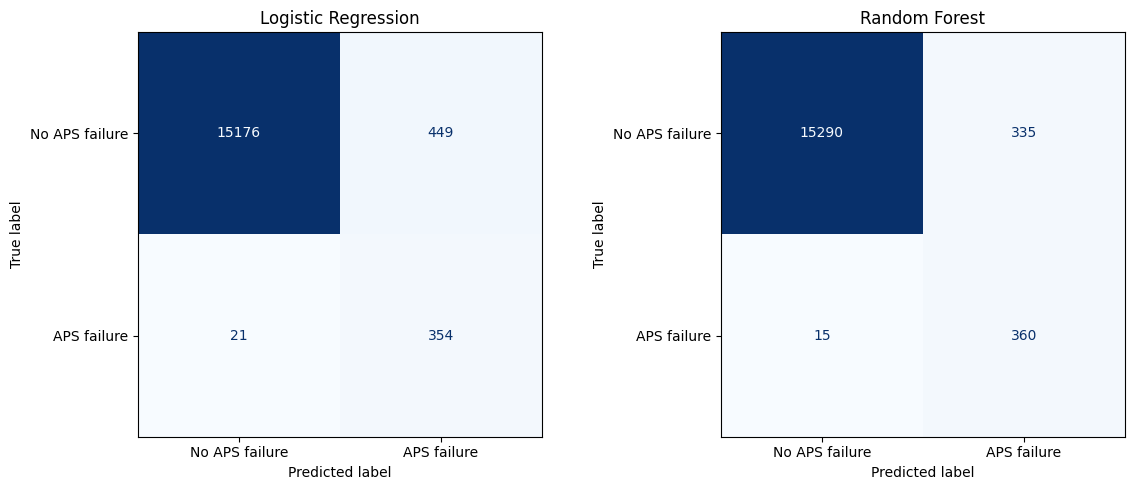

In [9]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred,
    display_labels=["No APS failure", "APS failure"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=["No APS failure", "APS failure"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()


In [10]:

from src.models.baseline import build_dummy_reference_classifier

# Create and train a simple reference model
dummy_model = build_dummy_reference_classifier()
dummy_model.fit(X_train, y_train)

# Predict on the test set
dummy_pred = dummy_model.predict(X_test)
dummy_prob = dummy_model.predict_proba(X_test)[:, 1]

# Same metrics as the other models
dummy_results = evaluate_binary_classifier(
    y_test, dummy_pred, dummy_prob
)

# Compare all three models
final_comparison = pd.DataFrame({
    "Dummy baseline": dummy_results,
    "Logistic Regression": lr_results,
    "Random Forest": rf_results
}).T

display(final_comparison.round(4))



,accuracy,precision,recall,f1,tn,fp,fn,tp,business_cost,pr_auc
Dummy baseline,0.9766,0.0000,0.000,0.0000,15625.0,0.0,375.0,0.0,187500.0,0.0234
Logistic Regression,0.9706,0.4408,0.944,0.6010,15176.0,449.0,21.0,354.0,14990.0,0.8016
Random Forest,0.9781,0.5180,0.960,0.6729,15290.0,335.0,15.0,360.0,10850.0,0.8989


## Interpretation and conclusion

### Dummy baseline

As a comparison we used a Dummy baseline that always predicts the most frequent class (no APS failure). It gets high accuracy but misses all 375 true APS failures and has a total **business cost** of 187,500. That shows why accuracy alone is misleading when positive cases are so rare.

### Results on the official test set

The final evaluation used Scania's official test set (16,000 observations, 375 APS failures). Both models were trained on the full training data with **frozen** settings and thresholds from model development (notebook 03).

Random Forest did better than Logistic Regression on the cost measure and most classification metrics in the table above.

### Cost-based comparison

**Total cost = 10 × FP + 500 × FN**

Logistic Regression: 14,990. Random Forest: 10,850 (about 27.6% lower cost). Random Forest missed fewer true failures (15 vs 21) and produced fewer false alarms (335 vs 449).

### Limitations

Random Forest still missed 15 true APS failures and produced 335 false positives. The model is **decision support**, not an automatic maintenance decision. Missing values, anonymised features, and historical data limit how far we can interpret the results.

### Conclusion

Random Forest is the best of the compared models on the official test set. Further validation on new, representative vehicle data is needed before the model could be used in operations without human review.
